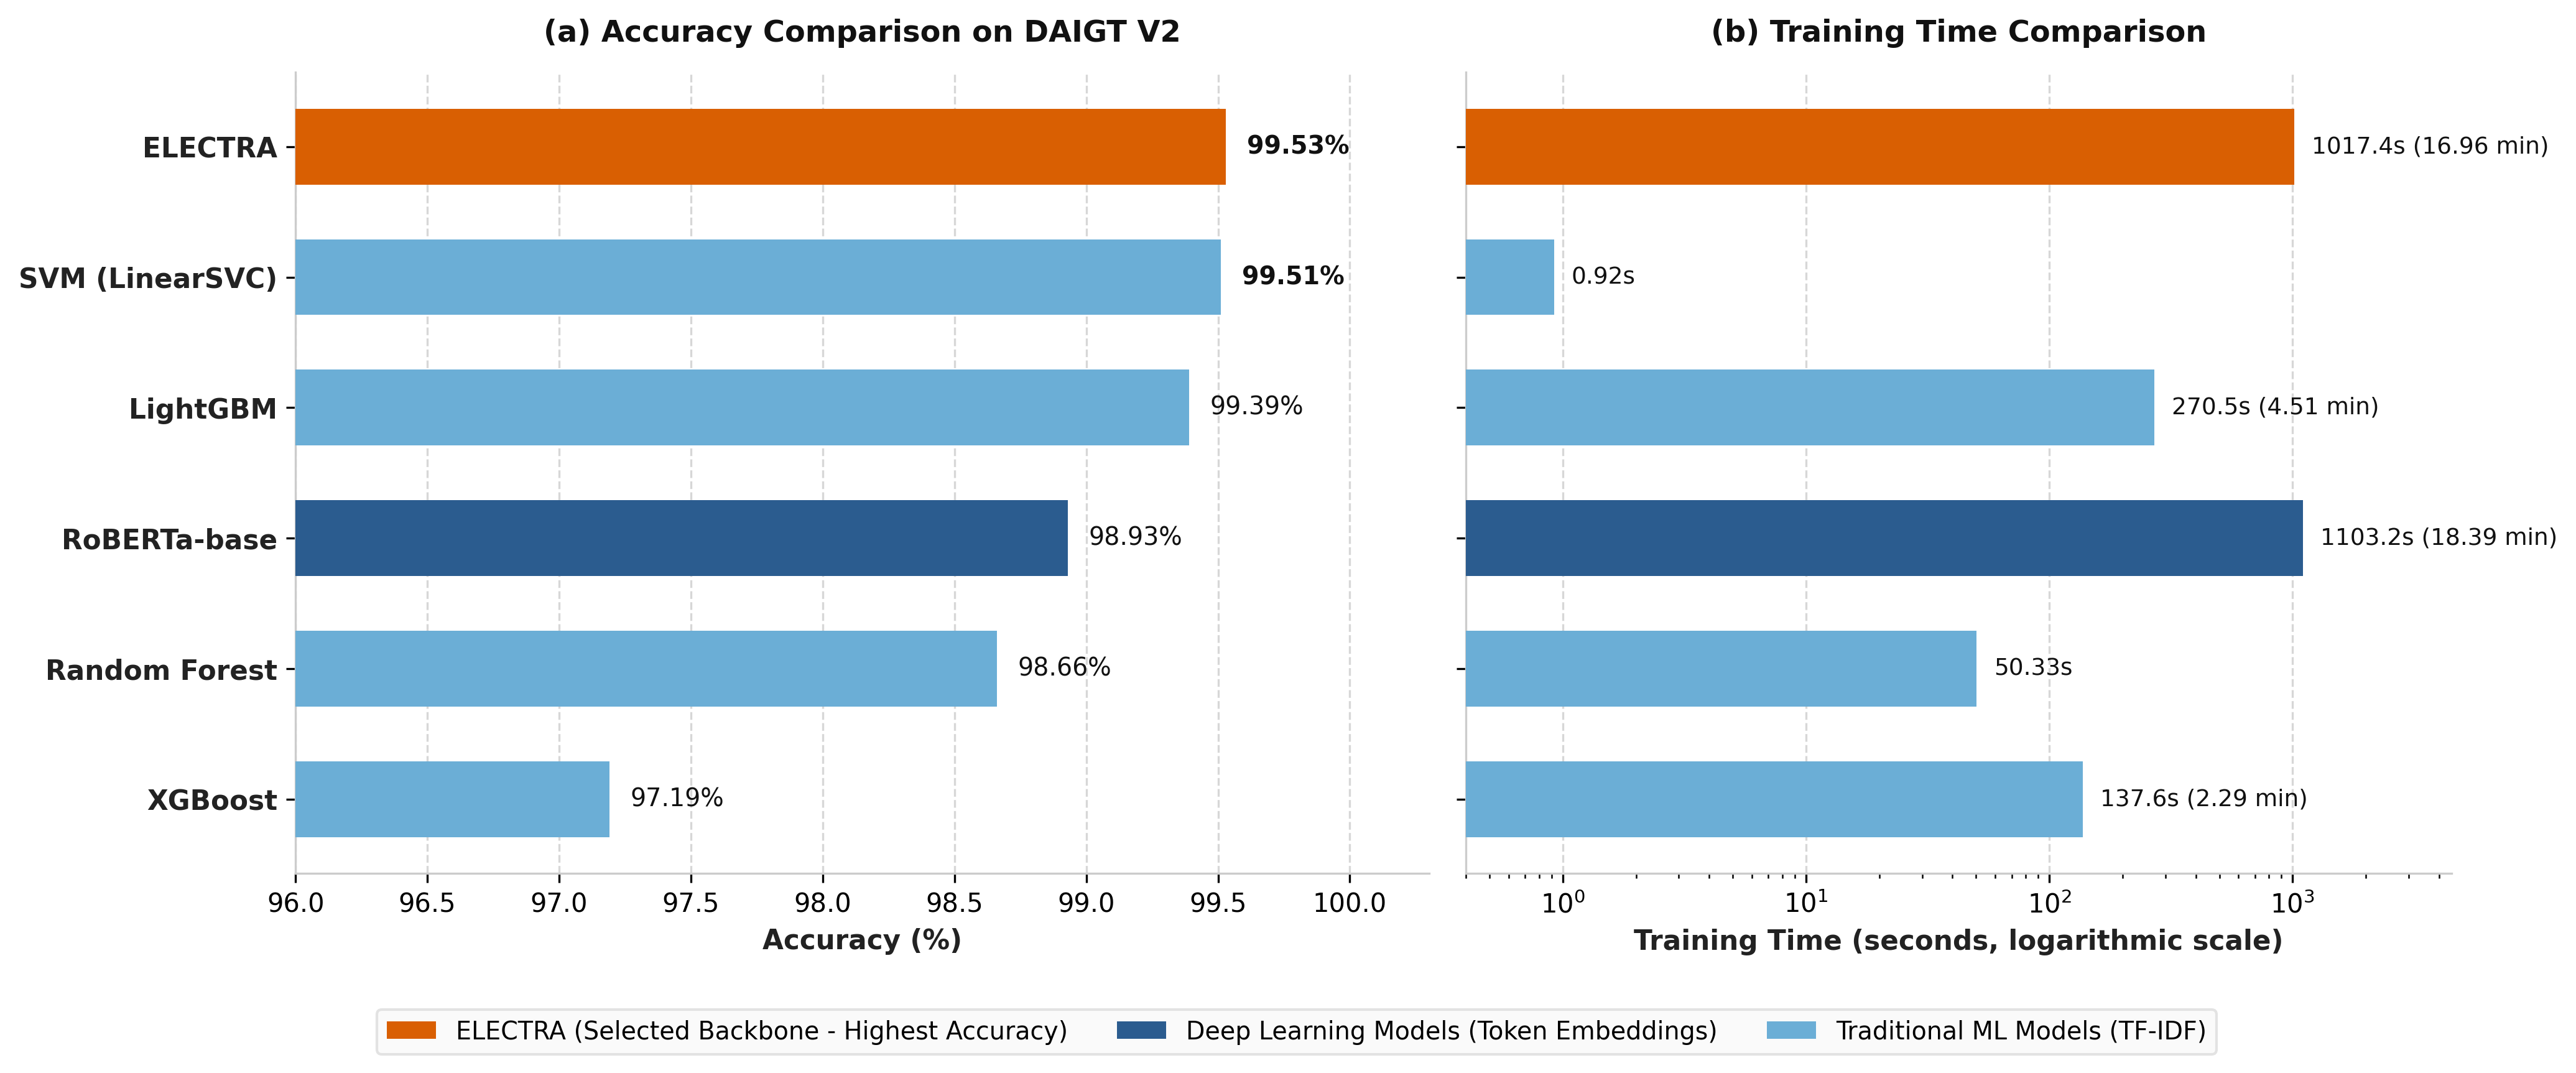

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import matplotlib.pyplot as plt  # Import Matplotlib for data visualization
import numpy as np  # Import NumPy for numerical operations
import pandas as pd  # Import Pandas for data manipulation

# 1. COMBINE RESULTS FROM TWO EXPERIMENTAL TABLES (STEP 1 - DAIGT V2)
data = [
    {"Model": "ELECTRA", "Type": "Deep Learning", "Acc": 99.53, "Time_s": 1017.4},  # ELECTRA experimental results
    {"Model": "SVM (LinearSVC)", "Type": "Traditional ML", "Acc": 99.51, "Time_s": 0.92},  # Linear SVM experimental results
    {"Model": "LightGBM", "Type": "Traditional ML", "Acc": 99.39, "Time_s": 270.5},  # LightGBM experimental results
    {"Model": "RoBERTa-base", "Type": "Deep Learning", "Acc": 98.93, "Time_s": 1103.2},  # RoBERTa experimental results
    {"Model": "Random Forest", "Type": "Traditional ML", "Acc": 98.66, "Time_s": 50.33},  # Random Forest experimental results
    {"Model": "XGBoost", "Type": "Traditional ML", "Acc": 97.19, "Time_s": 137.6},  # XGBoost experimental results
]

df = pd.DataFrame(data).sort_values("Acc", ascending=True).reset_index(drop=True)  # Create a DataFrame and sort models by accuracy

# 2. CONFIGURE THE VISUALIZATION STYLE
plt.rcParams["font.sans-serif"] = "DejaVu Sans"  # Set the default font family
plt.rcParams["axes.edgecolor"] = "#CCCCCC"  # Set the axes border color
plt.rcParams["axes.linewidth"] = 0.8  # Set the axes border thickness

fig, (ax1, ax2) = plt.subplots(
    1, 2,  # Create two subplots arranged horizontally
    figsize=(14, 5.6),  # Set the overall figure size
    dpi=300,  # Set the resolution to 300 DPI
    gridspec_kw={"width_ratios": [1.15, 1]}  # Adjust the relative widths of the subplots
)
fig.patch.set_facecolor("white")  # Set the figure background to white

# Define colors to distinguish model categories and highlight ELECTRA
colors = []  # Initialize the color list
for _, row in df.iterrows():  # Iterate through each model
    if row["Model"] == "ELECTRA":
        colors.append("#D95F02")  # Highlight the selected ELECTRA backbone in dark orange
    elif row["Type"] == "Deep Learning":
        colors.append("#2B5C8F")  # Use dark blue for deep learning models
    else:
        colors.append("#6BAED6")  # Use light blue for traditional machine learning models

y_pos = np.arange(len(df))  # Generate vertical positions for the bars

# --- CHART (a): MODEL ACCURACY (%) ---
bars1 = ax1.barh(
    y_pos, df["Acc"],  # Set bar positions and accuracy values
    height=0.58,  # Set the bar thickness
    color=colors,  # Apply the predefined model colors
    edgecolor="none",  # Remove bar borders
    zorder=3  # Draw bars above the grid
)
ax1.set_yticks(y_pos)  # Set the vertical axis positions
ax1.set_yticklabels(df["Model"], fontsize=10.5, fontweight="bold", color="#222222")  # Display model names
ax1.set_xlim(96.0, 100.3)  # Set the horizontal axis range
ax1.set_xlabel("Accuracy (%)", fontsize=10.5, fontweight="bold", color="#222222")  # Set the horizontal axis label
ax1.set_title("(a) Accuracy Comparison on DAIGT V2", fontsize=11.5, fontweight="bold", pad=12, color="#111111")  # Set the chart title
ax1.grid(axis="x", linestyle="--", alpha=0.5, zorder=0)  # Add a dashed vertical grid
ax1.spines["top"].set_visible(False)  # Hide the top border
ax1.spines["right"].set_visible(False)  # Hide the right border

# Add accuracy labels to each bar
for bar, (_, row) in zip(bars1, df.iterrows()):  # Iterate through bars and corresponding model results
    acc_val = row["Acc"]  # Retrieve the accuracy value
    weight = "bold" if row["Model"] in ["ELECTRA", "SVM (LinearSVC)"] else "normal"  # Highlight the two highest-accuracy models
    ax1.text(
        acc_val + 0.08,  # Position the label slightly to the right of the bar
        bar.get_y() + bar.get_height() / 2,  # Center the label vertically
        f"{acc_val:.2f}%",  # Format the accuracy as a percentage
        va="center",  # Align the label vertically
        ha="left",  # Align the label horizontally
        fontsize=9.5,  # Set the label font size
        fontweight=weight,  # Apply the selected font weight
        color="#111111",  # Set the label color
    )

# --- CHART (b): TRAINING TIME (SECONDS - LOGARITHMIC SCALE) ---
time_vals = df["Time_s"].fillna(0)  # Replace missing training times with zero
bars2 = ax2.barh(
    y_pos, time_vals,  # Set bar positions and training time values
    height=0.58,  # Set the bar thickness
    color=colors,  # Apply the same model colors
    edgecolor="none",  # Remove bar borders
    zorder=3  # Draw bars above the grid
)
ax2.set_xscale("log")  # Use a logarithmic scale to display different time ranges
ax2.set_xlim(0.4, 4500)  # Set the horizontal axis range
ax2.set_yticks(y_pos)  # Match the vertical positions with the first chart
ax2.set_yticklabels([""] * len(df))  # Hide duplicate model names on the second chart
ax2.set_xlabel("Training Time (seconds, logarithmic scale)", fontsize=10.5, fontweight="bold", color="#222222")  # Set the horizontal axis label
ax2.set_title("(b) Training Time Comparison", fontsize=11.5, fontweight="bold", pad=12, color="#111111")  # Set the chart title
ax2.grid(axis="x", linestyle="--", alpha=0.5, zorder=0)  # Add a dashed vertical grid
ax2.spines["top"].set_visible(False)  # Hide the top border
ax2.spines["right"].set_visible(False)  # Hide the right border

# Add actual training time labels
for idx, (_, row) in enumerate(df.iterrows()):  # Iterate through each model result
    t = row["Time_s"]  # Retrieve the training time
    if pd.isna(t):
        ax2.text(
            0.55, y_pos[idx], "No data recorded",  # Display a message for missing values
            va="center", ha="left", fontsize=9,
            style="italic", color="#666666"
        )
    else:
        label_str = f"{t:.2f}s" if t < 60 else f"{t:.1f}s ({t/60:.2f} min)"  # Format time in seconds or minutes
        ax2.text(
            t * 1.18, y_pos[idx], label_str,  # Position the label slightly to the right of the bar
            va="center", ha="left", fontsize=9, color="#111111"
        )

# Add a shared legend for both charts
from matplotlib.patches import Patch  # Import Patch to create custom legend entries

legend_elements = [
    Patch(facecolor="#D95F02", label="ELECTRA (Selected Backbone - Highest Accuracy)"),  # Highlight the selected model
    Patch(facecolor="#2B5C8F", label="Deep Learning Models (Token Embeddings)"),  # Identify deep learning models
    Patch(facecolor="#6BAED6", label="Traditional ML Models (TF-IDF)"),  # Identify traditional machine learning models
]

fig.legend(
    handles=legend_elements,  # Use the custom legend entries
    loc="lower center",  # Place the legend below both charts
    ncol=3,  # Arrange legend entries in three columns
    frameon=True,  # Display the legend frame
    facecolor="#F9F9F9",  # Set the legend background color
    edgecolor="#DDDDDD",  # Set the legend border color
    fontsize=9.5,  # Set the legend font size
    bbox_to_anchor=(0.5, -0.03),  # Adjust the legend position
)

plt.tight_layout(rect=[0, 0.05, 1, 1])  # Adjust spacing to prevent overlapping elements
output_file = "model_comparison_step1.png"  # Define the output image filename
plt.savefig(output_file, dpi=300, bbox_inches="tight")  # Save the figure at 300 DPI
plt.show()  # Display the charts

# Automatically download the image when running in Google Colab
try:
    from google.colab import files  # Import the Colab file management module
    files.download(output_file)  # Download the generated chart
except ImportError:
    print(f"Chart saved at: {output_file}")  # Display the local output path outside Colab


In [ ]:

import os  # Import the operating system module
import shutil  # Import the file copying module
import kagglehub  # Import KaggleHub for downloading datasets
from kagglehub import KaggleDatasetAdapter  # Import the Pandas dataset adapter

file_path = "train_v2_drcat_02.csv"  # Specify the CSV file to download
dataset_handle = "thedrcat/daigt-v2-train-dataset"  # Specify the Kaggle dataset identifier

print("Downloading dataset from Kaggle...")  # Display the download status

df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,  # Load the dataset as a Pandas DataFrame
    dataset_handle,  # Specify the Kaggle dataset
    file_path,  # Specify the file within the dataset
)

print("Download successful! DataFrame shape:", df.shape)  # Display the number of rows and columns

# Find the actual file location in the KaggleHub cache directory
local_dir = kagglehub.dataset_download(dataset_handle)  # Download the dataset and retrieve its local directory
downloaded_file = os.path.join(local_dir, file_path)  # Construct the full path to the downloaded CSV file

# Copy the file to the current working directory for easier access
output_name = "train_v2_drcat_02.csv"  # Define the output filename

if os.path.exists(downloaded_file) and downloaded_file != os.path.abspath(output_name):  # Check whether the source file exists
    shutil.copy(downloaded_file, output_name)  # Copy the file to the current directory
    print("File saved at:", os.path.abspath(output_name))  # Display the absolute file path

# Automatically download the file to your computer when running in Google Colab
try:
    from google.colab import files  # Import the Google Colab file management module
    print("Downloading the file to your computer...")  # Display the download status
    files.download(output_name)  # Trigger the file download
except ImportError:
    print("Running in a local or other environment: the file has been saved to the local disk.")  # Display the local environment message


/tmp/ipykernel_974/3792386541.py:11: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'daigt-v2-train-dataset' dataset.
Download successful! DataFrame shape: (44868, 5)
Using Colab cache for faster access to the 'daigt-v2-train-dataset' dataset.
File saved at: /content/train_v2_drcat_02.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import os  # Import the operating system module
import pandas as pd  # Import Pandas for data manipulation
from datasets import load_dataset  # Import the Hugging Face dataset loader

# 1. LOAD THE ONE-Lab/MixSet DATASET FROM HUGGING FACE

# Note: Run `huggingface-cli login` or provide a token if authentication is required
print("Loading the ONE-Lab/MixSet dataset...")  # Display the loading status
ds = load_dataset("ONE-Lab/MixSet")  # Download and load the dataset from Hugging Face
print("Available dataset splits:", list(ds.keys()))  # Display the available dataset splits

saved_files = []  # Initialize a list to store the names of saved CSV files

# 2. CONVERT EACH SPLIT INTO A DATAFRAME AND EXPORT IT AS A CSV FILE

for split_name, split_data in ds.items():  # Iterate through all dataset splits
    df_split = split_data.to_pandas()  # Convert the current split into a Pandas DataFrame
    csv_name = f"mixset_{split_name}.csv"  # Generate the output CSV filename
    df_split.to_csv(csv_name, index=False, encoding="utf-8-sig")  # Export the DataFrame as a UTF-8 CSV file
    saved_files.append(csv_name)  # Add the saved filename to the file list
    print(f"Saved {csv_name} | Shape: {df_split.shape}")  # Display the filename and dataset dimensions

# 3. OPTIONAL: CREATE A PREPROCESSED VERSION WITH NORMALIZED TARGET LABELS
# (MGT -> 1, HWT -> 0) USING THE 'revised' COLUMN

if "train" in ds:  # Check whether the training split exists
    df_train = ds["train"].to_pandas()  # Convert the training split into a DataFrame

    if "revised" in df_train.columns:  # Check whether the text column exists
        df_clean = df_train.dropna(subset=["revised"]).copy()  # Remove rows with missing text values

        # Normalize labels if a string or numerical label/target column exists
        for col in ["label", "target"]:  # Check possible label column names
            if col in df_clean.columns:  # Check whether the current column exists
                if df_clean[col].dtype == object:  # Check whether the labels are stored as strings
                    df_clean["target_norm"] = (
                        df_clean[col]  # Select the original label column
                        .astype(str)  # Convert all values to strings
                        .str.strip()  # Remove leading and trailing whitespace
                        .str.upper()  # Convert labels to uppercase
                        .map({"MGT": 1, "HWT": 0, "1": 1, "0": 0})  # Map labels to binary values
                    )
                break  # Stop after processing the first available label column

        clean_name = "mixset_train_prepared.csv"  # Define the output filename
        df_clean.to_csv(clean_name, index=False, encoding="utf-8-sig")  # Save the preprocessed training data
        saved_files.append(clean_name)  # Add the prepared filename to the file list
        print(f"Saved prepared dataset {clean_name} | Shape: {df_clean.shape}")  # Display the saved file information

# 4. AUTOMATICALLY DOWNLOAD FILES TO YOUR COMPUTER WHEN RUNNING IN GOOGLE COLAB

try:
    from google.colab import files  # Import the Google Colab file management module

    for f in saved_files:  # Iterate through all saved files
        if os.path.exists(f):  # Check whether the file exists
            print(f"Downloading {f} to your computer...")  # Display the download status
            files.download(f)  # Trigger the file download
except ImportError:
    print("Running outside Google Colab: all files have been saved in the current working directory.")  # Display the local environment message


Loading the ONE-Lab/MixSet dataset...


README.md:   0%|          | 0.00/4.07k [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


Mixset_train.json:   0%|          | 0.00/5.23M [00:00<?, ?B/s]

Mixset_test.json:   0%|          | 0.00/1.01M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/3000 [00:00<?, ? examples/s]

... (4 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>